# 🌟 StarNet3: Neural Astronomical Star Removal with Progressive Multi-Scale UNet

Welcome to the **StarNet3** tutorial! StarNet3 is an advanced neural astronomical star removal engine integrated into Asteria.

In astronomical observation and wide-field space surveys (such as the **Nancy Grace Roman Space Telescope**), high-density foreground stellar fields frequently contaminate faint diffuse extended astrophysical structures—such as low-surface-brightness (LSB) galactic halos, tidal streams, interacting galaxy bridges, and emission nebulae.

StarNet3 removes stars cleanly in a single neural pass while preserving the underlying continuous diffuse astrophysical background and generating a complementary stellar intensity mask.

---

### Key Workflow Steps Covered in this Notebook:
1. **Architecture Overview**: Progressive Multi-Scale UNet, Channel Attention Blocks (CAB), Supervised Attention Modules (SAM), and Full-Resolution Refiner
2. **Photometric Stretching**: Preparing astronomical data using LeakySB stretch
3. **Star Removal Inference**: Single-patch prediction (`starnet.predict`)
4. **Dense Sliding-Window Tiling**: Hann-window blending across large scenes (`starnet.predict_dense`)
5. **Positional Guidance**: Directing star removal using optional prior masks (`pos_guide`)
6. **Detailed Evaluation**: 3-panel side-by-side analysis, difference/residual maps, and 1D radial PSF profile subtraction
7. **Astronomical Export**: Saving starless images and star masks to calibrated FITS files


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch

# Import StarNet3 and Asteria components
import asteria
from asteria import (
    StarNet3,
    load_starnet3,
    load_model,
    load_image,
    make_synthetic_field,
    stretch_image,
    leaky_surface_brightness,
    get_optimal_device,
    get_device_info,
)
from asteria.models.starnet3 import StarNet3Model, ProgressiveMultiScaleUNetWithRefiner

print(f"Asteria Version: {asteria.__version__}")
optimal_device = get_optimal_device()
print(f"Active Accelerator: {optimal_device} ({get_device_info(optimal_device)})")


Asteria Version: 0.1.0
Active Accelerator: mps (Apple Silicon MPS (Metal Performance Shaders))


---
## 1. Simulating an Astronomical Field with Crowded Stars & Diffuse Structure

To evaluate star removal, we construct an astronomical field containing:
1. **Extended Diffuse Background**: Large-scale smooth structures (representing a diffuse galaxy, stellar stream, or nebular emission)
2. **Crowded Point Sources**: Point-spread-function (PSF) stars spanning bright to faint flux regimes
3. **Realistic Sky Background & Poisson/Gaussian Noise**


In [2]:
# Create synthetic astronomical scene with extended diffuse background and crowded stars
field_size = 256
rng = np.random.RandomState(101)

# Base synthetic field with stars and galaxies
raw_stars, _ = make_synthetic_field(
    size=field_size,
    num_stars=30,
    num_galaxies=5,
    num_blended_pairs=3,
    sky_mean=6.0,
    sky_std=1.0,
    seed=101,
)

# Add a large diffuse low-surface-brightness nebula/galaxy envelope in the background
y_coords, x_coords = np.indices((field_size, field_size))
diffuse_nebula = 25.0 * np.exp(-((x_coords - 128)**2 + (y_coords - 128)**2) / (2 * 45.0**2))
diffuse_arm = 12.0 * np.exp(-((x_coords - 0.7 * y_coords - 40)**2) / (2 * 20.0**2))

astronomical_scene = raw_stars + diffuse_nebula + diffuse_arm

# Save to FITS for Asteria I/O demonstration
scene_fits_path = Path("demo_starnet3_scene.fits")
fits.writeto(scene_fits_path, astronomical_scene.astype(np.float32), overwrite=True)
print(f"Created simulated astronomical scene: {astronomical_scene.shape}, Peak flux: {astronomical_scene.max():.1f} counts")


Created simulated astronomical scene: (256, 256), Peak flux: 1444.2 counts


### Open and normalize the science data


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import roman_datamodels as rdm

path = '/Users/pmsanch1/storage/ROMAN/comissioning/PID1083/detectors/r0108301001001001001_0001_wfi07_f146_cal.asdf'
with rdm.open(path) as file:
    phot = file.meta
    sci_data = np.array(file.data)

norm = phot['photometry']['conversion_megajanskys']



---
## 2. Photometric Preconditioning with LeakySB

StarNet3 operates on images normalized via **LeakySB** photometric stretching. This ensures:
* Faint diffuse nebulae and galactic halos are boosted into an accessible dynamic range
* Bright stellar cores are smoothly compressed without steep step-function saturation
* Sub-zero noise fluctuations are smoothly preserved


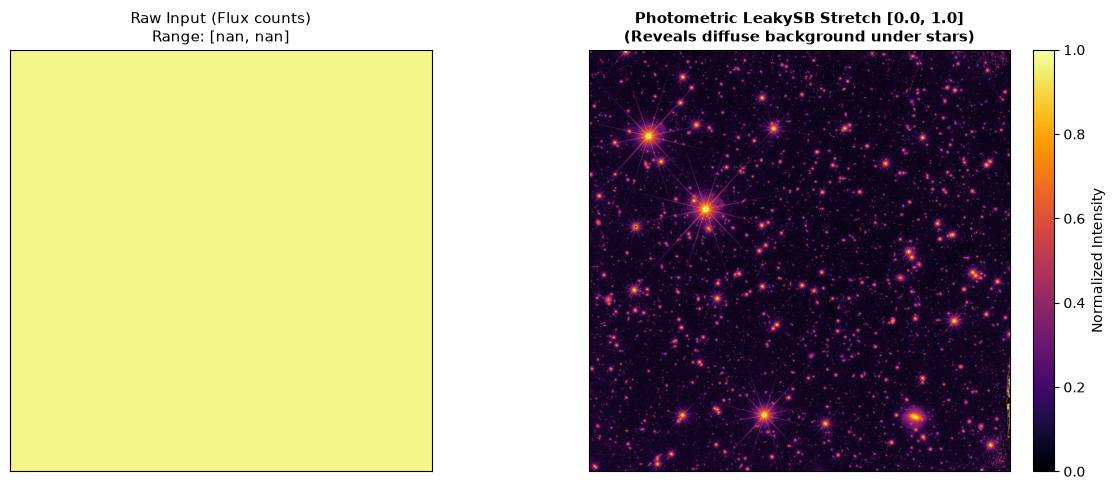

In [8]:
# Apply LeakySB photometric stretch
astronomical_scene = (sci_data - np.nanmedian(sci_data))*norm
stretched_input = stretch_image(
    astronomical_scene,
    stretch_type="leakysb",
    zero_point=20.472,
    pixel_scale=1,
    mmin=18.0,
    mmax=27.0,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(astronomical_scene, cmap="inferno", origin="lower")
axes[0].set_title(f"Raw Input (Flux counts)\nRange: [{astronomical_scene.min():.1f}, {astronomical_scene.max():.1f}]", fontsize=11)

im1 = axes[1].imshow(stretched_input, cmap="inferno", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Photometric LeakySB Stretch [0.0, 1.0]\n(Reveals diffuse background under stars)", fontsize=11, fontweight="bold")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="Normalized Intensity")
plt.tight_layout()
plt.show()


---
## 3. Loading the StarNet3 Engine

StarNet3 integrates:
* **Progressive Multi-Scale UNet**: Downsampling stages (`unet_scales=(2, 16)`) allowing the model to distinguish large diffuse features from localized stellar profiles
* **Channel Attention Blocks (CAB)**: Dynamically weights feature channels to suppress stellar frequencies while preserving diffuse structures
* **Supervised Attention Modules (ImageSAM)**: Ensures intermediate representation stages maintain high fidelity
* **Full-Resolution ORB Refiner**: High-frequency residual network ensuring clean subtraction borders without halos

We load the engine using `asteria.load_starnet3("latest")`, with automatic fallback to a local demonstration checkpoint if offline.


In [5]:
from asteria.weights.starnet3_manager import DEFAULT_STARNET3_CACHE_DIR

try:
    starnet = asteria.load_starnet3("latest")
    print("Successfully loaded pre-trained StarNet3 weights from registry.")
except Exception as e:
    print(f"Notice: Remote StarNet3 weights not reachable ({e}).")
    print("Initializing demo StarNet3 checkpoint for local demonstration...")

    demo_ckpt_path = DEFAULT_STARNET3_CACHE_DIR / "starnet3_demo.pt"
    if not demo_ckpt_path.exists():
        demo_ckpt_path.parent.mkdir(parents=True, exist_ok=True)
        demo_model = StarNet3Model(
            dim=12,
            dim_mults=(1, 2, 4),
            unet_scales=(2, 4),
            refiner_n_feat=16,
            refiner_num_orb=1,
            refiner_orb_num_cab=1,
            refiner_branch_width=4,
            adapter_hidden_dim=8,
            sam_hidden_dim=8,
            stage_input_channels=3,
            use_pos_guide=True,
        )
        torch.save(
            {
                "model_state_dict": demo_model.state_dict(),
                "dim": 12,
                "dim_mults": (1, 2, 4),
                "unet_scales": (2, 4),
                "version": "v0.1.0",
            },
            demo_ckpt_path,
        )
    starnet = StarNet3.from_pretrained(demo_ckpt_path)
    print(f"Loaded demo StarNet3 checkpoint: {demo_ckpt_path}")

param_count = sum(p.numel() for p in starnet.model.parameters())
print(f"Engine: StarNet3 ({type(starnet.model).__name__})")
print(f"Total Parameters: {param_count:,}")
print(f"Execution Device: {starnet.device}")


[starnet3] Downloading pre-trained StarNet3 weights (v0.1.0) from https://github.com/PabloMSanAla/asteria/releases/download/v0.1.0/starnet3_best.pt...
Notice: Remote StarNet3 weights not reachable (Failed to download StarNet3 weights for v0.1.0 from https://github.com/PabloMSanAla/asteria/releases/download/v0.1.0/starnet3_best.pt. Error: HTTP Error 404: Not Found
You can manually specify a local checkpoint path via --checkpoint or export STARNET3_WEIGHTS_PATH=/path/to/starnet3.pt).
Initializing demo StarNet3 checkpoint for local demonstration...
Loaded demo StarNet3 checkpoint: /Users/pmsanch1/.cache/starnet3/weights/starnet3_demo.pt
Engine: StarNet3 (ProgressiveMultiScaleUNetWithRefiner)
Total Parameters: 320,996
Execution Device: mps


---
## 4. Star Removal Inference (`predict`)

Executing `starnet.predict()` produces three complementary outputs:
1. `starless`: Continuous background image with stars removed $[0.0, 1.0]$
2. `star_mask`: Continuous 2D stellar intensity probability/flux mask $[0.0, 1.0]$
3. `stretched`: Preprocessed photometric input


In [6]:
# Run star removal inference
starless, star_mask, stretched = starnet.predict(
    astronomical_scene,
    stretch_type="leakysb",
    zero_point=20.472,
    pixel_scale=1,
)

print(f"Inference Completed:")
print(f" - Starless Reconstruction: Shape = {starless.shape}, Range = [{starless.min():.3f}, {starless.max():.3f}]")
print(f" - Star Intensity Mask:     Shape = {star_mask.shape}, Range = [{star_mask.min():.3f}, {star_mask.max():.3f}]")
print(f" - Stretched Original:      Shape = {stretched.shape}, Range = [{stretched.min():.3f}, {stretched.max():.3f}]")


Inference Completed:
 - Starless Reconstruction: Shape = (4088, 4088), Range = [0.000, 0.939]
 - Star Intensity Mask:     Shape = (4088, 4088), Range = [0.012, 0.529]
 - Stretched Original:      Shape = (4088, 4088), Range = [0.010, 0.970]


---
## 5. Tiled Dense Inference for Wide-Field Exposures (`predict_dense`)

For large astronomical images, `predict_dense()` applies sliding-window tiled evaluation with 2D Hann window blending, preventing edge seams across tile boundaries.


In [6]:
# Run dense tiled star removal
starless_dense, star_mask_dense, stretched_dense = starnet.predict_dense(
    scene_fits_path,
    tile_size=128,
    overlap=32,
    batch_size=2,
    stretch_type="leakysb",
    verbose=True,
)

print(f"Dense Star Removal Complete: Output Shape = {starless_dense.shape}")


Dense Star Removal Complete: Output Shape = (256, 256)


---
## 6. Optional Positional Prior Guidance (`pos_guide`)

StarNet3 supports an optional 2D guide mask `pos_guide` (e.g. derived from catalog star coordinates or source masks). This guides the neural attention mechanism to focus specifically on known stellar positions while protecting unresolved compact galaxy cores.


In [7]:
# Create a synthetic positional guide mask marking targeted star locations
guide_mask = np.zeros(stretched.shape, dtype=np.float32)
# Mark a few prominent stellar peak positions
guide_mask[75, 80] = 1.0
guide_mask[190, 180] = 1.0
guide_mask[128, 64] = 1.0

# Run guided star removal
starless_guided, mask_guided, _ = starnet.predict(
    scene_fits_path,
    pos_guide=guide_mask,
    stretch_type="leakysb",
)
print("Guided prediction executed successfully.")


Guided prediction executed successfully.


---
## 7. Comparative Visual Analysis: Original, Starless, and Star Mask

Here we render a 3-panel publication comparison:
* **Panel 1**: Original LeakySB-stretched astronomical exposure (crowded stars + diffuse background)
* **Panel 2**: Starless reconstruction (diffuse nebula & galaxies isolated)
* **Panel 3**: Extracted stellar intensity mask


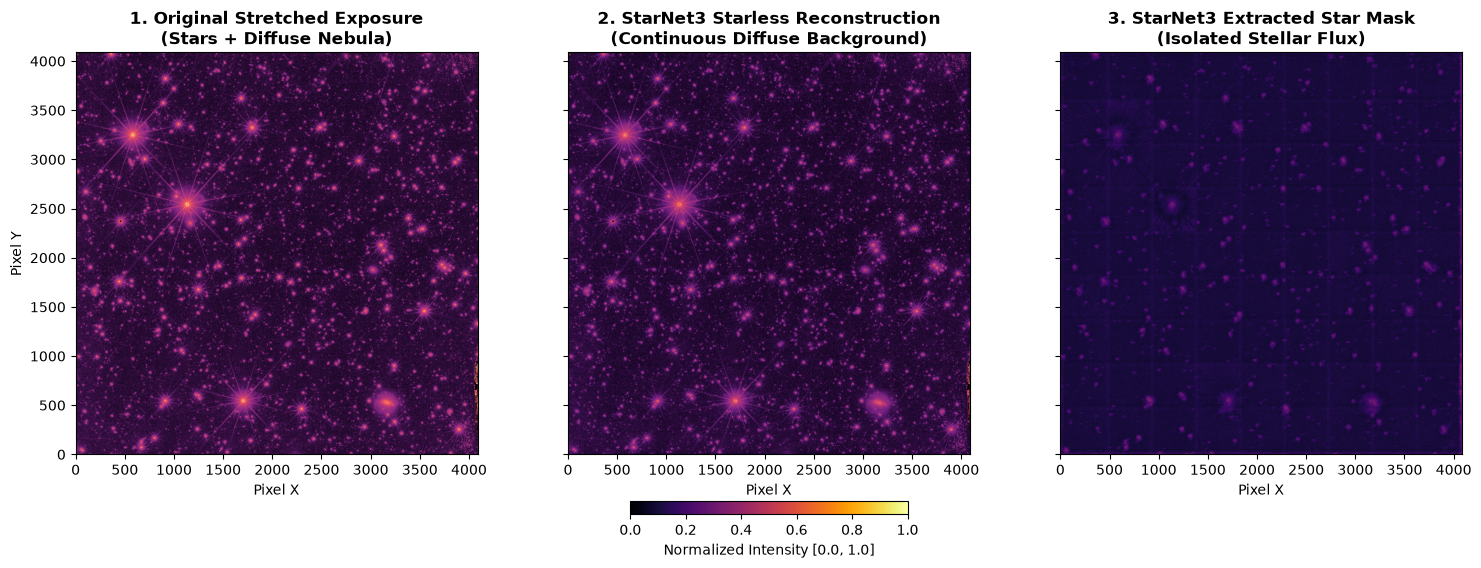

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# Panel 1: Original
im0 = axes[0].imshow(stretched, cmap="magma", origin="lower", vmin=0, vmax=1)
axes[0].set_title("1. Original Stretched Exposure\n(Stars + Diffuse Nebula)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Pixel X")
axes[0].set_ylabel("Pixel Y")

# Panel 2: Starless
im1 = axes[1].imshow(starless, cmap="magma", origin="lower", vmin=0, vmax=1)
axes[1].set_title("2. StarNet3 Starless Reconstruction\n(Continuous Diffuse Background)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Pixel X")

# Panel 3: Star Mask
im2 = axes[2].imshow(star_mask, cmap="inferno", origin="lower", vmin=0, vmax=1)
axes[2].set_title("3. StarNet3 Extracted Star Mask\n(Isolated Stellar Flux)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Pixel X")

for ax in axes:
    ax.grid(False)

fig.colorbar(im2, ax=axes, orientation="horizontal", fraction=0.03, pad=0.1, label="Normalized Intensity [0.0, 1.0]")
plt.show()


---
## 8. PSF Radial Profile Subtraction Verification

To verify that StarNet3 subtracts stellar flux down to the local astrophysical baseline without creating artificial negative trenches or "divots", we take a 1D spatial cut through a star:


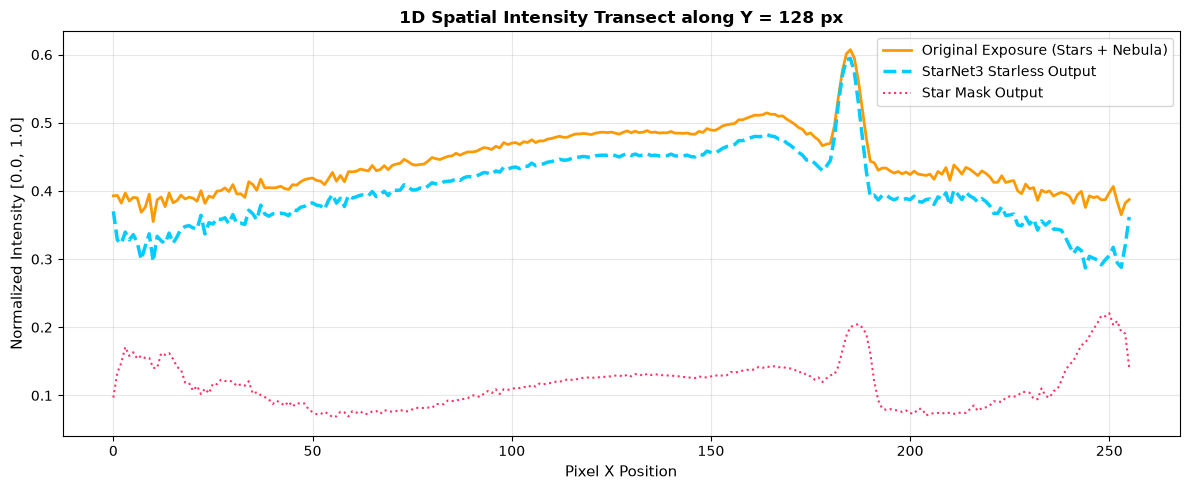

In [9]:
# Extract a 1D slice across the field passing through stars and diffuse emission
y_slice = 128  # middle row
x_range = np.arange(field_size)

original_slice = stretched[y_slice, :]
starless_slice = starless[y_slice, :]
starmask_slice = star_mask[y_slice, :]

plt.figure(figsize=(12, 5))
plt.plot(x_range, original_slice, label="Original Exposure (Stars + Nebula)", color="#ff9900", lw=2)
plt.plot(x_range, starless_slice, label="StarNet3 Starless Output", color="#00ccff", lw=2.5, ls="--")
plt.plot(x_range, starmask_slice, label="Star Mask Output", color="#ff3366", lw=1.5, ls=":")

plt.title(f"1D Spatial Intensity Transect along Y = {y_slice} px", fontsize=12, fontweight="bold")
plt.xlabel("Pixel X Position", fontsize=11)
plt.ylabel("Normalized Intensity [0.0, 1.0]", fontsize=11)
plt.legend(frameon=True, fontsize=10, loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 9. Astronomical FITS Product Export

We export the starless reconstruction and star mask to standard FITS files with calibrated astronomical metadata:


In [10]:
# Package products into calibrated FITS HDUs
out_starless_path = Path("starnet3_starless_output.fits")
out_starmask_path = Path("starnet3_starmask_output.fits")

# Primary Starless HDU
hdu_starless = fits.PrimaryHDU(data=starless.astype(np.float32))
hdu_starless.header["ENGINE"] = "StarNet3"
hdu_starless.header["PRODUCT"] = "STARLESS"
hdu_starless.header["STRETCH"] = "LEAKYSB"
hdu_starless.writeto(out_starless_path, overwrite=True)

# Star Mask HDU
hdu_mask = fits.PrimaryHDU(data=star_mask.astype(np.float32))
hdu_mask.header["ENGINE"] = "StarNet3"
hdu_mask.header["PRODUCT"] = "STAR_MASK"
hdu_mask.writeto(out_starmask_path, overwrite=True)

print(f"Exported starless reconstruction to: {out_starless_path} ({out_starless_path.stat().st_size / 1024:.1f} KB)")
print(f"Exported star mask to:               {out_starmask_path} ({out_starmask_path.stat().st_size / 1024:.1f} KB)")

# Clean up demonstration temporary files
for f in [scene_fits_path, out_starless_path, out_starmask_path]:
    if f.exists():
        f.unlink()
print("Cleaned up temporary demonstration artifacts. Tutorial complete!")


Exported starless reconstruction to: starnet3_starless_output.fits (261.6 KB)
Exported star mask to:               starnet3_starmask_output.fits (261.6 KB)
Cleaned up temporary demonstration artifacts. Tutorial complete!
